<a href="https://colab.research.google.com/github/RizkiHadiono/244107020198-Pembelajaran-Mesin/blob/main/JS06_ANN_244107020198_MOKHAMAD_RIZKI_HADIONO_SINGGIH.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Jobsheet Praktikum ANN

**Praktikum 1–6 dan Tugas: Exact Nearest Neighbor, Annoy, FAISS, dan HNSWLIB.**


## Persiapan library

In [1]:
!pip -q install annoy faiss-cpu hnswlib

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 11.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 26.1 MB/s eta 0:00:00


In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from annoy import AnnoyIndex
import faiss
import hnswlib
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

# Praktikum 1 — Exact NN vs Annoy
Data 2D acak. Ubah jumlah data, tree, dan metrik untuk membandingkan hasil. Waktu build indeks dan waktu query dicatat terpisah.

Metric: euclidean | Tree: 3 | Data: 1000
Exact index: [317 381 119] | Annoy index: [317, 381, 119]
Exact query: 12.9652 ms | Build Annoy: 0.0086 s | Annoy query: 0.0297 ms


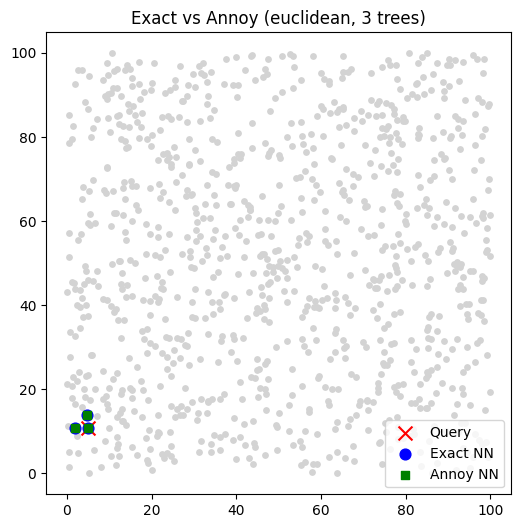

In [3]:
def compare_annoy(n=1000, dim=2, metric="euclidean", trees=3, k=3, seed=42):
    rng = np.random.default_rng(seed)
    X = (rng.random((n, dim))*100).astype("float32")
    q = X[rng.integers(n)]
    start = time.perf_counter()
    if metric == "euclidean":
        dist = np.linalg.norm(X-q, axis=1)
    else:
        den = np.linalg.norm(X, axis=1)*np.linalg.norm(q)
        sim = np.divide(X@q, den, out=np.zeros(n), where=den!=0)
        dist = 1-np.clip(sim, -1, 1)
    exact = np.argsort(dist)[:k]
    exact_ms = (time.perf_counter()-start)*1000
    idx = AnnoyIndex(dim, metric)
    for i, row in enumerate(X): idx.add_item(i, row.tolist())
    start = time.perf_counter(); idx.build(trees); build_s = time.perf_counter()-start
    start = time.perf_counter(); approx = idx.get_nns_by_vector(q.tolist(), k); query_ms=(time.perf_counter()-start)*1000
    print("Metric:", metric, "| Tree:", trees, "| Data:", n)
    print("Exact index:", exact, "| Annoy index:", approx)
    print(f"Exact query: {exact_ms:.4f} ms | Build Annoy: {build_s:.4f} s | Annoy query: {query_ms:.4f} ms")
    if dim == 2:
        plt.figure(figsize=(6,6)); plt.scatter(X[:,0],X[:,1],c="lightgray",s=15)
        plt.scatter(q[0],q[1],c="red",marker="x",s=100,label="Query")
        plt.scatter(X[exact,0],X[exact,1],c="blue",s=60,label="Exact NN")
        plt.scatter(X[approx,0],X[approx,1],c="green",marker="s",s=40,label="Annoy NN")
        plt.legend(); plt.title(f"Exact vs Annoy ({metric}, {trees} trees)"); plt.show()
    return [metric, trees, n, str(exact), str(approx), exact_ms, build_s, query_ms]

hasil1 = compare_annoy()


Metric: euclidean | Tree: 8 | Data: 1000
Exact index: [317 381 119] | Annoy index: [317, 381, 119]
Exact query: 0.1974 ms | Build Annoy: 0.0304 s | Annoy query: 0.0478 ms


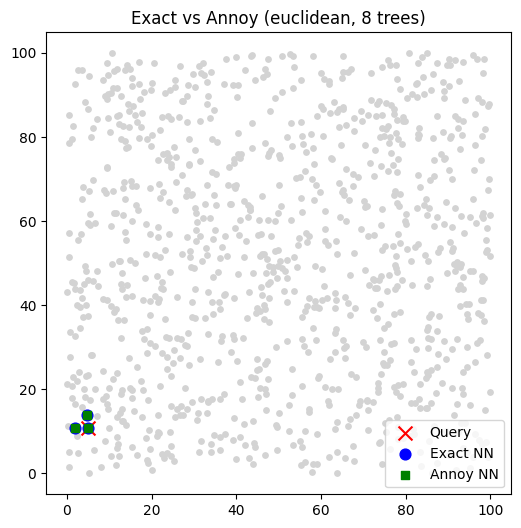

Metric: euclidean | Tree: 3 | Data: 100000
Exact index: [75453  2977 81227] | Annoy index: [75453, 2977, 81227]
Exact query: 6.9007 ms | Build Annoy: 0.8666 s | Annoy query: 0.0338 ms


/usr/local/lib/python3.13/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


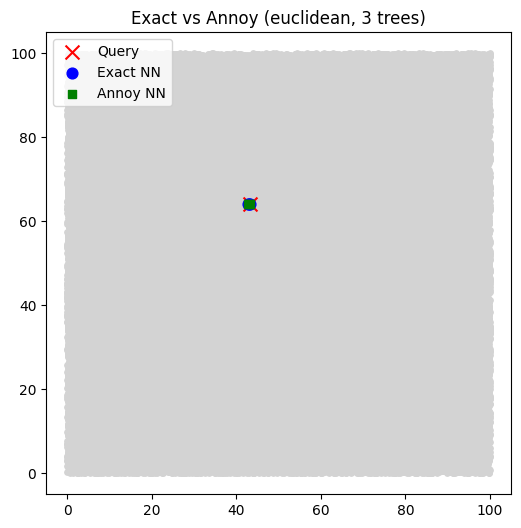

Metric: angular | Tree: 3 | Data: 1000
Exact index: [317 411  38] | Annoy index: [317, 411, 38]
Exact query: 4.6123 ms | Build Annoy: 0.0425 s | Annoy query: 0.0308 ms


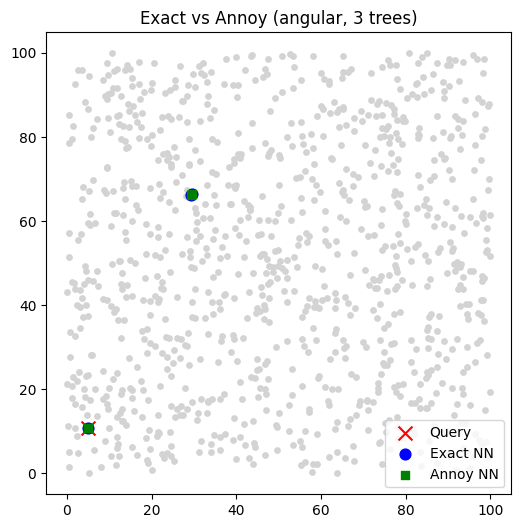

Metric: angular | Tree: 8 | Data: 1000
Exact index: [317 411  38] | Annoy index: [317, 411, 38]
Exact query: 0.2673 ms | Build Annoy: 0.0520 s | Annoy query: 0.0433 ms


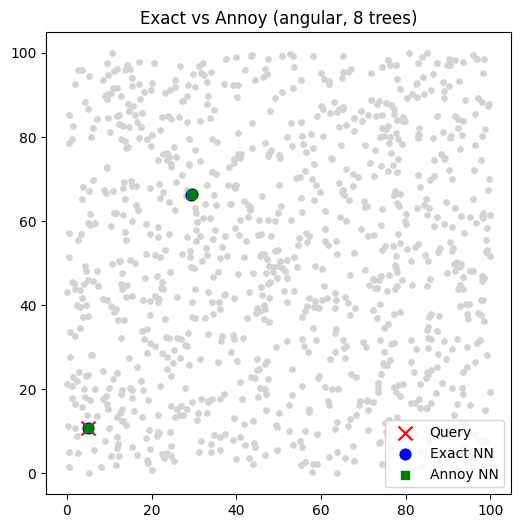

Metric: angular | Tree: 3 | Data: 100000
Exact index: [59766 24241 42125] | Annoy index: [24241, 28028, 7524]
Exact query: 52.8796 ms | Build Annoy: 4.5906 s | Annoy query: 0.0402 ms


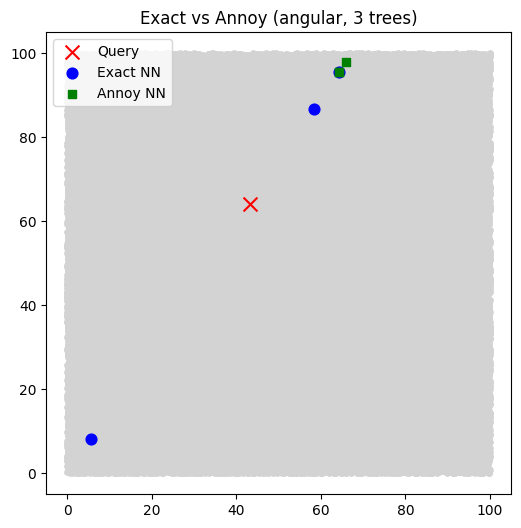

,Metric,Tree,Jumlah data,Exact index,Annoy index,Exact ms,Build s,Annoy query ms
0,euclidean,8,1000,[317 381 119],"[317, 381, 119]",0.197382,0.030351,0.047753
1,euclidean,3,100000,[75453 2977 81227],"[75453, 2977, 81227]",6.900678,0.866600,0.033773
2,angular,3,1000,[317 411 38],"[317, 411, 38]",4.612307,0.042467,0.030756
3,angular,8,1000,[317 411 38],"[317, 411, 38]",0.267257,0.052037,0.043336
4,angular,3,100000,[59766 24241 42125],"[24241, 28028, 7524]",52.879649,4.590637,0.040224


In [4]:
# Variasi sesuai tabel jobsheet. 100.000 data membutuhkan waktu lebih lama.
rows = []
for metric, trees, n in [
    ("euclidean", 8, 1000), ("euclidean", 3, 100_000),
    ("angular", 3, 1000), ("angular", 8, 1000), ("angular", 3, 100_000)
]:
    rows.append(compare_annoy(n=n, metric=metric, trees=trees))
pd.DataFrame(rows, columns=["Metric","Tree","Jumlah data","Exact index","Annoy index","Exact ms","Build s","Annoy query ms"])


### Simulasi track rekomendasi dan pertanyaan build index
Contoh jobsheet berisi 50 juta track, yang dapat menghabiskan RAM Colab. Mulai dari 100.000 data; naikkan bertahap jika cukup memori.

In [5]:
N_TRACKS = 100_000  # ubah ke 1_000_000 jika RAM mencukupi
N_FEATURES, K = 20, 5
rng = np.random.default_rng(42)
X = rng.random((N_TRACKS,N_FEATURES), dtype=np.float32)
q = rng.random(N_FEATURES,dtype=np.float32)
start=time.perf_counter(); dist=np.linalg.norm(X-q,axis=1); exact=np.argsort(dist)[:K]; t_exact=time.perf_counter()-start
idx=AnnoyIndex(N_FEATURES,"euclidean")
for i,row in enumerate(X): idx.add_item(i,row.tolist())
start=time.perf_counter(); idx.build(8); t_build=time.perf_counter()-start
start=time.perf_counter(); approx=idx.get_nns_by_vector(q.tolist(),K); t_query=time.perf_counter()-start
print("Exact:",exact,"time:",round(t_exact,4),"s")
print("Annoy:",approx,"build:",round(t_build,4),"s","query:",round(t_query,6),"s")


Exact: [42475 60179 89511 12356 20932] time: 0.0205 s
Annoy: [2138, 87873, 82792, 28824, 65442] build: 1.2007 s query: 0.000183 s


**Jawaban:** Waktu build index tidak dimasukkan ke waktu query karena build adalah tahap persiapan indeks, sedangkan query mengukur pencarian setelah indeks siap. Untuk biaya penggunaan keseluruhan, laporkan build time dan query time, atau jumlahkan keduanya.

# Praktikum 2 — FAISS Flat vs IVF
`IndexFlatL2` mencari secara eksak. `IndexIVFFlat` membagi data ke inverted lists; `nprobe` menentukan jumlah list yang dicari.

In [6]:
def compare_faiss(n=1000, dim=2, nlist=10, nprobe=5, k=3, seed=42):
    rng=np.random.default_rng(seed); X=rng.random((n,dim),dtype=np.float32); q=rng.random((1,dim),dtype=np.float32)
    flat=faiss.IndexFlatL2(dim); start=time.perf_counter(); flat.add(X); flat_add=time.perf_counter()-start
    start=time.perf_counter(); D,I=flat.search(q,k); t_flat=time.perf_counter()-start
    nl=min(nlist,max(1,n//10)); ivf=faiss.IndexIVFFlat(faiss.IndexFlatL2(dim),dim,nl,faiss.METRIC_L2)
    start=time.perf_counter(); ivf.train(X); ivf.add(X); t_build=time.perf_counter()-start
    ivf.nprobe=min(nprobe,nl); start=time.perf_counter(); Di,Ii=ivf.search(q,k); t_ivf=time.perf_counter()-start
    recall=len(set(I[0])&set(Ii[0]))/k
    print("Data/dim:",n,dim,"nlist/nprobe:",nl,ivf.nprobe)
    print("Flat:",I[0],"IVF:",Ii[0],"Recall@k:",round(recall,3))
    print(f"Flat query {t_flat*1000:.4f} ms | IVF build {t_build:.4f} s | IVF query {t_ivf*1000:.4f} ms")
    return [n,dim,recall,t_flat*1000,t_build,t_ivf*1000]
compare_faiss()


Data/dim: 1000 2 nlist/nprobe: 10 5
Flat: [258  17 971] IVF: [258  17 971] Recall@k: 1.0
Flat query 0.1274 ms | IVF build 0.0031 s | IVF query 0.0824 ms


[1000, 2, 1.0, 0.12739800001781987, 0.0031297929999709595, 0.08243800004947843]

In [7]:
# Variasi jumlah data dan dimensi
pd.DataFrame([compare_faiss(n,dim,nlist=100,nprobe=10,k=5) for n,dim in [(1000,2),(1000,5),(100_000,2),(100_000,5)]],
             columns=["Data","Dimensi","Recall@5","Flat query ms","IVF build s","IVF query ms"])


Data/dim: 1000 2 nlist/nprobe: 100 10
Flat: [258  17 971 187 794] IVF: [258  17 971 187 794] Recall@k: 1.0
Flat query 0.0422 ms | IVF build 0.0122 s | IVF query 0.0567 ms
Data/dim: 1000 5 nlist/nprobe: 100 10
Flat: [812  34 550 962 251] IVF: [812  34 550 962 251] Recall@k: 1.0
Flat query 0.0318 ms | IVF build 0.0127 s | IVF query 0.0628 ms
Data/dim: 100000 2 nlist/nprobe: 100 10
Flat: [66214 81343   173 53419 18680] IVF: [66214 81343 53419   173 18680] Recall@k: 1.0
Flat query 3.4334 ms | IVF build 0.3191 s | IVF query 0.2090 ms
Data/dim: 100000 5 nlist/nprobe: 100 10
Flat: [77470 42836  9332 23520 50922] IVF: [77470 42836  9332 23520 50922] Recall@k: 1.0
Flat query 7.2600 ms | IVF build 0.1138 s | IVF query 0.2053 ms


,Data,Dimensi,Recall@5,Flat query ms,IVF build s,IVF query ms
0,1000,2,1.0,0.042180,0.012246,0.056651
1,1000,5,1.0,0.031785,0.012740,0.062812
2,100000,2,1.0,3.433402,0.319110,0.209033
3,100000,5,1.0,7.260018,0.113840,0.205269


# Praktikum 3 — Exact NN vs HNSWLIB
HNSW membangun graf pencarian. `M`, `ef_construction`, dan `ef` mengatur kompromi memori, waktu build, dan akurasi.

In [8]:
def compare_hnsw(n=1000, dim=2, k=5, ef=50, seed=42):
    rng=np.random.default_rng(seed); X=rng.random((n,dim),dtype=np.float32); q=rng.random((1,dim),dtype=np.float32)
    exact=NearestNeighbors(n_neighbors=k,algorithm="brute",metric="euclidean"); exact.fit(X)
    start=time.perf_counter(); de,ie=exact.kneighbors(q); te=time.perf_counter()-start
    h=hnswlib.Index(space="l2",dim=dim); start=time.perf_counter()
    h.init_index(max_elements=n,ef_construction=100,M=16); h.add_items(X); tb=time.perf_counter()-start
    h.set_ef(max(ef,k)); start=time.perf_counter(); ih,dh=h.knn_query(q,k=k); tq=time.perf_counter()-start
    recall=len(set(ie[0])&set(ih[0]))/k
    print("Exact:",ie[0],"HNSW:",ih[0],"Recall@k:",round(recall,3))
    print(f"Exact query {te*1000:.4f} ms | HNSW build {tb:.4f} s | HNSW query {tq*1000:.4f} ms")
    return [n,dim,ef,recall,te*1000,tb,tq*1000]
compare_hnsw()


Exact: [258  17 971 187 794] HNSW: [258  17 971 187 794] Recall@k: 1.0
Exact query 49.3094 ms | HNSW build 0.0422 s | HNSW query 0.0660 ms


[1000,
 2,
 50,
 1.0,
 49.309417000017675,
 0.04219452199993157,
 0.06595299998934934]

In [9]:
pd.DataFrame([compare_hnsw(n,dim,k=5,ef=50) for n,dim in [(1000,2),(1000,5),(100_000,2),(100_000,5)]],
             columns=["Data","Dimensi","ef","Recall@5","Exact query ms","HNSW build s","HNSW query ms"])


Exact: [258  17 971 187 794] HNSW: [258  17 971 187 794] Recall@k: 1.0
Exact query 0.5385 ms | HNSW build 0.0478 s | HNSW query 0.0613 ms
Exact: [812  34 550 962 251] HNSW: [812  34 550 962 251] Recall@k: 1.0
Exact query 1.7759 ms | HNSW build 0.0529 s | HNSW query 0.0745 ms
Exact: [66214 81343 53419   173 18680] HNSW: [66214 81343 53419   173 18680] Recall@k: 1.0
Exact query 5.3452 ms | HNSW build 4.0971 s | HNSW query 0.0683 ms
Exact: [77470 42836  9332 23520 50922] HNSW: [77470 42836  9332 23520 50922] Recall@k: 1.0
Exact query 4.1465 ms | HNSW build 5.5383 s | HNSW query 0.0775 ms


,Data,Dimensi,ef,Recall@5,Exact query ms,HNSW build s,HNSW query ms
0,1000,2,50,1.0,0.538452,0.047784,0.061331
1,1000,5,50,1.0,1.775876,0.052894,0.074523
2,100000,2,50,1.0,5.345188,4.097150,0.068259
3,100000,5,50,1.0,4.146478,5.538349,0.077529


# Praktikum 4 — Perbandingan Annoy, FAISS, HNSW
Gunakan dataset yang sama agar perbandingan lebih adil. Default 100.000 data; ubah ke 1.000.000 bila RAM mencukupi.

In [10]:
N_DATA,DIM,K=100_000,5,10
rng=np.random.default_rng(42); X=rng.random((N_DATA,DIM),dtype=np.float32); q=rng.random((1,DIM),dtype=np.float32)
# Annoy
a=AnnoyIndex(DIM,"euclidean")
for i,row in enumerate(X): a.add_item(i,row.tolist())
start=time.perf_counter(); a.build(10); a_build=time.perf_counter()-start
start=time.perf_counter(); a_ids=a.get_nns_by_vector(q[0].tolist(),K); a_query=time.perf_counter()-start
# FAISS Flat
f=faiss.IndexFlatL2(DIM); start=time.perf_counter(); f.add(X); f_build=time.perf_counter()-start
start=time.perf_counter(); fd,fi=f.search(q,K); f_query=time.perf_counter()-start
# HNSW
h=hnswlib.Index(space="l2",dim=DIM); start=time.perf_counter(); h.init_index(max_elements=N_DATA,ef_construction=200,M=16); h.add_items(X); h_build=time.perf_counter()-start
h.set_ef(50); start=time.perf_counter(); hi,hd=h.knn_query(q,k=K); h_query=time.perf_counter()-start
pd.DataFrame([
["Annoy",a_build,a_query,str(a_ids[:5])],
["FAISS Flat",f_build,f_query,str(fi[0][:5].tolist())],
["HNSW",h_build,h_query,str(hi[0][:5].tolist())]
],columns=["Metode","Build time (s)","Query time (s)","Contoh 5 indeks"])


,Metode,Build time (s),Query time (s),Contoh 5 indeks
0,Annoy,1.600500,0.000172,"[77470, 42836, 9332, 23520, 50922]"
1,FAISS Flat,0.000812,0.002704,"[77470, 42836, 9332, 23520, 50922]"
2,HNSW,10.984567,0.000154,"[77470, 42836, 9332, 23520, 50922]"


**Analisis:** FAISS Flat adalah pencarian eksak dan memeriksa seluruh vektor saat query. Annoy dan HNSW adalah approximate nearest neighbor, sehingga dapat lebih cepat tetapi hasilnya tidak selalu identik. Parameter indeks memengaruhi trade-off waktu dan akurasi.

# Praktikum 5 — Benchmark Recall vs Waktu Query
Recall@k adalah proporsi tetangga hasil ANN yang juga ditemukan exact search. Grafik di bawah membandingkan recall dengan waktu query (ms/query); waktu lebih kecil lebih baik.

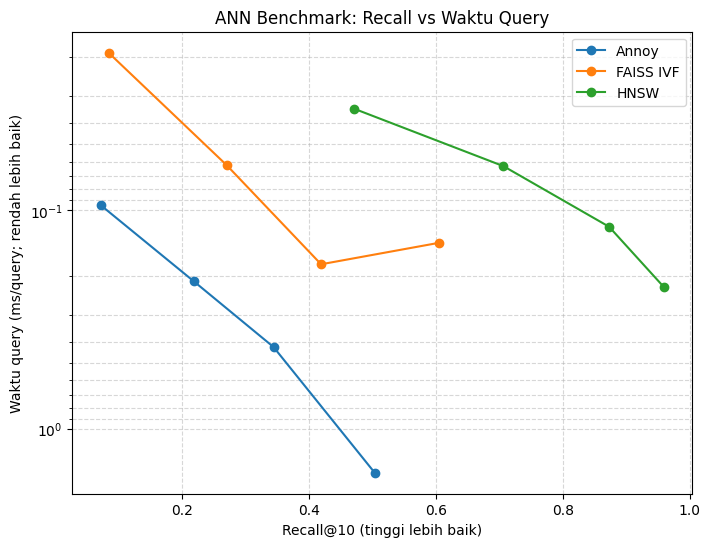

,Metode,Parameter,Recall@10,Waktu ms/query,QPS perkiraan
0,Annoy,search_k=100,0.0715,0.094687,10561.104066
1,Annoy,search_k=500,0.2180,0.210800,4743.837743
2,Annoy,search_k=1000,0.3440,0.421819,2370.683399
3,Annoy,search_k=2000,0.5035,1.584843,630.977449
4,FAISS IVF,nprobe=1,0.0840,0.019030,52549.518724
5,FAISS IVF,nprobe=5,0.2700,0.062106,16101.492214
6,FAISS IVF,nprobe=10,0.4190,0.176522,5665.018345
7,FAISS IVF,nprobe=20,0.6050,0.140798,7102.350409
8,HNSW,ef=20,0.4705,0.034268,29181.773706
9,HNSW,ef=50,0.7065,0.062833,15915.231657


In [12]:
d,nb,nq,k=64,20_000,200,10
rng=np.random.default_rng(42); xb=rng.random((nb,d),dtype=np.float32); xq=rng.random((nq,d),dtype=np.float32)
flat=faiss.IndexFlatL2(d); flat.add(xb); _,gt=flat.search(xq,k)
def recall_at_k(pred, truth, k):
    total = 0

    for i in range(len(pred)):
        hasil_prediksi = set(map(int, pred[i][:k]))
        hasil_aktual = set(map(int, truth[i][:k]))

        jumlah_sama = len(hasil_prediksi & hasil_aktual)
        total += jumlah_sama

    return total / (len(pred) * k)
results={"Annoy":[],"FAISS IVF":[],"HNSW":[]}; rows=[]
for sk in [100,500,1000,2000]:
    idx=AnnoyIndex(d,"euclidean")
    for i,row in enumerate(xb): idx.add_item(i,row.tolist())
    idx.build(10); start=time.perf_counter()
    pred=[idx.get_nns_by_vector(row.tolist(),k,search_k=sk) for row in xq]
    ms=(time.perf_counter()-start)*1000/nq; results["Annoy"].append((recall_at_k(pred,gt,k),ms,f"search_k={sk}"))
for npb in [1,5,10,20]:
    idx=faiss.IndexIVFFlat(faiss.IndexFlatL2(d),d,100,faiss.METRIC_L2); idx.train(xb); idx.add(xb); idx.nprobe=npb
    start=time.perf_counter(); _,pred=idx.search(xq,k); ms=(time.perf_counter()-start)*1000/nq
    results["FAISS IVF"].append((recall_at_k(pred,gt,k),ms,f"nprobe={npb}"))
for ef in [20,50,100,200]:
    idx=hnswlib.Index(space="l2",dim=d); idx.init_index(max_elements=nb,ef_construction=150,M=16); idx.add_items(xb); idx.set_ef(max(ef,k))
    start=time.perf_counter(); pred,_=idx.knn_query(xq,k=k); ms=(time.perf_counter()-start)*1000/nq
    results["HNSW"].append((recall_at_k(pred,gt,k),ms,f"ef={ef}"))
plt.figure(figsize=(8,6))
for method,vals in results.items():
    plt.plot([v[0] for v in vals],[v[1] for v in vals],marker="o",label=method)
    for rec,ms,param in vals: rows.append([method,param,rec,ms,1000/ms if ms else np.nan])
plt.xlabel("Recall@10 (tinggi lebih baik)"); plt.ylabel("Waktu query (ms/query; rendah lebih baik)")
plt.yscale("log"); plt.gca().invert_yaxis(); plt.title("ANN Benchmark: Recall vs Waktu Query")
plt.grid(True,which="both",linestyle="--",alpha=.5); plt.legend(); plt.show()
pd.DataFrame(rows,columns=["Metode","Parameter","Recall@10","Waktu ms/query","QPS perkiraan"])


**Interpretasi:** posisi dengan recall tinggi dan waktu query rendah lebih baik. Menaikkan `search_k`, `nprobe`, atau `ef` biasanya meningkatkan recall, namun bisa memperlambat pencarian. Hasil harus diambil dari output aktual runtime.

# Praktikum 6 — Dataset Spotify

**Input dataset:** jalankan sel berikut untuk mengunggah file dataset Spotify berformat `.csv` dari komputer ke Google Colab. Setelah file diunggah, notebook menampilkan nama file, ukuran dataset, dan nama kolomnya. Gunakan dataset CSV Spotify yang diminta pada jobsheet.

Pastikan file memiliki fitur audio numerik seperti `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, dan `tempo`.


In [14]:
# INPUT DATASET CSV — klik Choose Files lalu pilih file Spotify (.csv)
from google.colab import files
uploaded = files.upload()

csv_files = [name for name in uploaded.keys() if name.lower().endswith(".csv")]
if not csv_files:
    raise ValueError("File CSV belum diunggah. Jalankan ulang sel ini dan pilih dataset Spotify berformat .csv.")

# Jika lebih dari satu CSV diunggah, gunakan file CSV pertama
CSV_PATH = csv_files[0]
df = pd.read_csv(CSV_PATH)
print("Dataset yang digunakan:", CSV_PATH)
print("Ukuran dataset (baris, kolom):", df.shape)
print("Daftar kolom:")
print(df.columns.tolist())
display(df.head())


Saving songs_with_attributes_and_lyrics.csv to songs_with_attributes_and_lyrics.csv
Dataset yang digunakan: songs_with_attributes_and_lyrics.csv
Ukuran dataset (baris, kolom): (955320, 17)
Daftar kolom:
['id', 'name', 'album_name', 'artists', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'duration_ms', 'lyrics']


,id,name,album_name,artists,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms,lyrics
0,0Prct5TDjAnEgIqbxcldY9,!,UNDEN!ABLE,HELLYEAH,0.415,0.6050,7,-11.157,1,0.0575,0.00116,0.838000,0.4710,0.193,100.059,79500.0,"He said he came from Jamaica,\n he owned a cou..."
1,2ASl4wirkeYm3OWZxXKYuq,!!,NaN,Yxngxr1,0.788,0.6480,7,-9.135,0,0.3150,0.90000,0.000000,0.1760,0.287,79.998,114000.0,"Fucked a bitch, now she running with my kids\n..."
2,69lcggVPmOr9cvPx9kLiiN,!!! - Interlude,Where I Belong EP,Glowie,0.000,0.0354,7,-20.151,0,0.0000,0.90800,0.000000,0.4790,0.000,0.000,11413.0,"Oh, my God, I'm going crazy\n"
3,4U7dlZjg1s9pjdppqZy0fm,!!De Repente!!,Un Palo Al Agua (20 Grandes Canciones),Rosendo,0.657,0.8820,5,-6.340,1,0.0385,0.00740,0.000013,0.0474,0.939,123.588,198173.0,Continuamente se extraña la gente si no puede ...
4,4v1IBp3Y3rpkWmWzIlkYju,!!De Repente!!,Fuera De Lugar,Rosendo,0.659,0.8930,5,-8.531,1,0.0411,0.09220,0.000019,0.0534,0.951,123.600,199827.0,Continuamente se extraña la gente si no puede ...


In [15]:
# Pilih fitur audio numerik sesuai jobsheet, lalu bersihkan dan normalisasi data
features = ["danceability", "energy", "loudness", "speechiness", "acousticness",
            "instrumentalness", "liveness", "valence", "tempo"]
missing = [c for c in features if c not in df.columns]
if missing:
    raise ValueError(
        "Kolom fitur berikut tidak ditemukan: " + str(missing) +
        ". Pastikan CSV yang diunggah adalah dataset Spotify yang sesuai jobsheet. "
        "Periksa nama kolom pada output sel sebelumnya."
    )

Xdf = df[features].apply(pd.to_numeric, errors="coerce")
Xdf = Xdf.replace([np.inf, -np.inf], np.nan).dropna()
if len(Xdf) < 2:
    raise ValueError("Data valid kurang dari 2 baris. Periksa dataset CSV.")

# Batasi jumlah baris agar proses tetap memungkinkan di Colab
MAX_ROWS = 100_000
if MAX_ROWS and len(Xdf) > MAX_ROWS:
    Xdf = Xdf.sample(n=MAX_ROWS, random_state=42)

scaler = StandardScaler()
X = scaler.fit_transform(Xdf).astype("float32")
n, dim = X.shape
k = min(10, n)
nq = min(n, 1000)
print("Fitur yang digunakan:", features)
print("Ukuran data setelah pembersihan dan normalisasi:", X.shape)
print("Jumlah query:", nq, "| k:", k)


Fitur yang digunakan: ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
Ukuran data setelah pembersihan dan normalisasi: (100000, 9)
Jumlah query: 1000 | k: 10


In [16]:
# Perbandingan Exact NN, Annoy, HNSWLIB, dan FAISS IVF
# Exact NN
nn = NearestNeighbors(n_neighbors=k, algorithm="brute", metric="euclidean")
start = time.perf_counter(); nn.fit(X); exact_fit = time.perf_counter() - start
start = time.perf_counter(); de, ie = nn.kneighbors(X[:nq]); exact_q = time.perf_counter() - start

# Annoy
annoy_index = AnnoyIndex(dim, "euclidean")
for i, row in enumerate(X):
    annoy_index.add_item(i, row.tolist())
start = time.perf_counter(); annoy_index.build(10); annoy_build = time.perf_counter() - start
start = time.perf_counter()
ia = [annoy_index.get_nns_by_vector(row.tolist(), k) for row in X[:nq]]
annoy_q = time.perf_counter() - start

# HNSWLIB
h = hnswlib.Index(space="l2", dim=dim)
start = time.perf_counter()
h.init_index(max_elements=n, ef_construction=200, M=16)
h.add_items(X)
h_build = time.perf_counter() - start
h.set_ef(max(200, k))
start = time.perf_counter(); ih, dh = h.knn_query(X[:nq], k=k); h_q = time.perf_counter() - start

# FAISS IVF
nlist = min(100, max(1, n // 100))
ivf = faiss.IndexIVFFlat(faiss.IndexFlatL2(dim), dim, nlist, faiss.METRIC_L2)
start = time.perf_counter(); ivf.train(X); ivf.add(X); faiss_build = time.perf_counter() - start
ivf.nprobe = min(10, nlist)
start = time.perf_counter(); df_dist, ifx = ivf.search(X[:nq], k); faiss_q = time.perf_counter() - start

print("Top-5 tetangga untuk data pertama (indeks baris):")
print("Exact NN :", ie[0][:5])
print("Annoy    :", ia[0][:5])
print("HNSWLIB  :", ih[0][:5])
print("FAISS IVF:", ifx[0][:5])

hasil_praktikum6 = pd.DataFrame([
    ["Exact NN", exact_fit, exact_q, nq],
    ["Annoy", annoy_build, annoy_q, nq],
    ["HNSWLIB", h_build, h_q, nq],
    ["FAISS IVF", faiss_build, faiss_q, nq]
], columns=["Metode", "Waktu fit/build (detik)", "Waktu query (detik)", "Jumlah query"])
display(hasil_praktikum6)


Top-5 tetangga untuk data pertama (indeks baris):
Exact NN : [    0 39320 87041  6847 86813]
Annoy    : [0, 39320, 87041, 6847, 86813]
HNSWLIB  : [    0 39320 87041  6847 86813]
FAISS IVF: [    0 39320 87041  6847 86813]


,Metode,Waktu fit/build (detik),Waktu query (detik),Jumlah query
0,Exact NN,0.014106,1.164522,1000
1,Annoy,1.894788,0.039490,1000
2,HNSWLIB,14.874622,0.105573,1000
3,FAISS IVF,0.086256,0.122921,1000


### Analisis Praktikum 6

- **Exact NN:** menjadi pembanding pencarian eksak; pencarian dapat semakin lama ketika jumlah data bertambah.
- **Annoy:** menggunakan pohon untuk pencarian tetangga terdekat perkiraan.
- **HNSWLIB:** menggunakan graf; parameter indeks memengaruhi waktu, memori, dan kualitas hasil.
- **FAISS IVF:** membagi vektor ke beberapa inverted lists; `nlist` dan `nprobe` memengaruhi proses pencarian.
- Bandingkan waktu build/fit dan waktu query secara terpisah. Waktu query di sini dihitung untuk jumlah query yang tercetak pada output.
- Indeks yang ditampilkan adalah nomor baris dalam data yang sudah dibersihkan, bukan nama lagu. Jika dataset memiliki kolom judul lagu, gunakan indeks tersebut untuk menelusuri lagu terkait.


# Tugas — Bandingkan Google Colab dan PyDroid3
Menjalankan kode pada kedua lingkungan jika library berhasil diinstal. Pada Android, instalasi `faiss-cpu` atau `hnswlib` mungkin gagal bergantung versi Python/arsitektur. Catat error jika gagal; jangan mengarang hasil.

In [17]:
np.random.seed(42)
n_samples,d,k=10_000,128,10
X=np.random.random((n_samples,d)).astype("float32")
X=StandardScaler().fit_transform(X).astype("float32")
start=time.perf_counter()
nn=NearestNeighbors(n_neighbors=k,algorithm="brute",metric="euclidean"); nn.fit(X); _,idx_exact=nn.kneighbors(X)
time_exact=time.perf_counter()-start
print(f"Exact NN done in {time_exact:.3f} s")
start=time.perf_counter()
a=AnnoyIndex(d,"euclidean")
for i,row in enumerate(X): a.add_item(i,row.tolist())
a.build(10); idx_a=[a.get_nns_by_vector(row.tolist(),k) for row in X]
time_a=time.perf_counter()-start
print(f"Annoy done in {time_a:.3f} s")
start=time.perf_counter()
h=hnswlib.Index(space="l2",dim=d); h.init_index(max_elements=n_samples,ef_construction=200,M=16); h.add_items(X); h.set_ef(200); idx_h,_=h.knn_query(X,k=k)
time_h=time.perf_counter()-start
print(f"HNSW done in {time_h:.3f} s")
start=time.perf_counter()
ivf=faiss.IndexIVFFlat(faiss.IndexFlatL2(d),d,100,faiss.METRIC_L2); ivf.train(X); ivf.add(X); ivf.nprobe=10; _,idx_f=ivf.search(X,k)
time_f=time.perf_counter()-start
print(f"FAISS IVF done in {time_f:.3f} s")
print("\n=== Ringkasan Waktu (detik) ===")
print(f"Exact NN : {time_exact:.3f}\nAnnoy    : {time_a:.3f}\nHNSW     : {time_h:.3f}\nFAISS    : {time_f:.3f}")


Exact NN done in 1.117 s
Annoy done in 0.376 s
HNSW done in 5.743 s
FAISS IVF done in 0.641 s

=== Ringkasan Waktu (detik) ===
Exact NN : 1.117
Annoy    : 0.376
HNSW     : 5.743
FAISS    : 0.641
